In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

In [ ]:
path=kagglehub.dataset_download("harshadapatil31/student-performance-and-study-habits-dataset")

Using Colab cache for faster access to the 'student-performance-and-study-habits-dataset' dataset.


In [ ]:
os.listdir(path)

['student_performance_dataset.csv']

In [ ]:
#df=pd.read_csv(os.path.join(path, 'student_performance_dataset.csv') ,low_memory=False)
df=pd.read_csv(path + '/student_performance_dataset.csv',low_memory=False)

In [ ]:
df

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D
...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,Male,2.8,75.4,8.2,Masters,Yes,Yes,No,60.5,70.7,C
996,997,Male,6.7,88.4,7.1,NaN,No,Yes,No,82.2,99.5,A
997,998,Female,2.6,84.5,8.0,High School,Yes,Yes,Yes,65.2,79.2,C
998,999,Female,4.6,85.3,8.1,High School,No,No,Yes,52.2,82.2,B


# Data cleaning

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   object 
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    object 
 6   internet_access             1000 non-null   object 
 7   extracurricular_activities  1000 non-null   object 
 8   part_time_job               1000 non-null   object 
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   object 
dtypes: float64(5), int64(1), object(6)
memory usage: 93.9+ KB


In [ ]:
df.isnull().sum()

,0
student_id,0
gender,0
study_time_hours,0
attendance_percent,0
sleep_hours,0
parental_education,102
internet_access,0
extracurricular_activities,0
part_time_job,0
previous_grade,0


In [ ]:
df["parental_education"]=df.parental_education.fillna(df['parental_education'].mode)
df.isnull().sum()

,0
student_id,0
gender,0
study_time_hours,0
attendance_percent,0
sleep_hours,0
parental_education,0
internet_access,0
extracurricular_activities,0
part_time_job,0
previous_grade,0


In [ ]:
df

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,<bound method Series.mode of 0 Bachelor...,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D
...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,Male,2.8,75.4,8.2,Masters,Yes,Yes,No,60.5,70.7,C
996,997,Male,6.7,88.4,7.1,<bound method Series.mode of 0 Bachelor...,No,Yes,No,82.2,99.5,A
997,998,Female,2.6,84.5,8.0,High School,Yes,Yes,Yes,65.2,79.2,C
998,999,Female,4.6,85.3,8.1,High School,No,No,Yes,52.2,82.2,B


In [ ]:
round(df.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
student_id,1000.0,500.50,288.82,1.0,250.75,500.5,750.25,1000.0
study_time_hours,1000.0,3.57,1.48,0.5,2.60,3.6,4.50,8.1
attendance_percent,1000.0,85.09,9.27,54.8,78.80,85.2,91.90,100.0
sleep_hours,1000.0,6.80,1.20,3.2,5.90,6.8,7.60,10.0
previous_grade,1000.0,69.74,12.61,31.3,61.00,69.6,78.40,100.0
final_exam_score,1000.0,83.54,10.34,46.8,76.07,83.8,91.52,100.0


In [ ]:
df.duplicated().sum()

np.int64(0)

# Exploratory Data Analysis

In [ ]:
numerical_cols=df.select_dtypes(include='number').columns.to_list()
numerical_cols.pop(0)

'student_id'

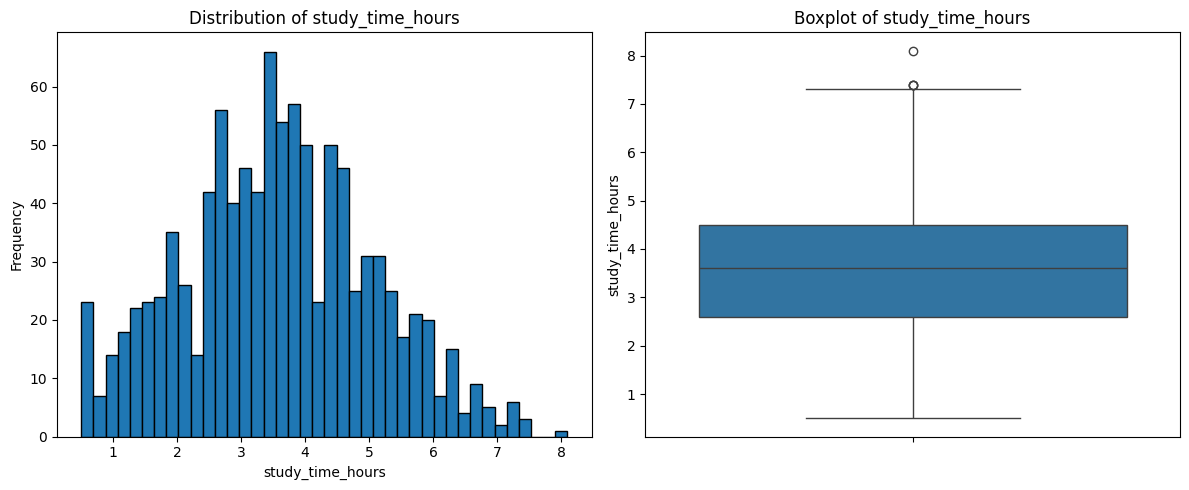

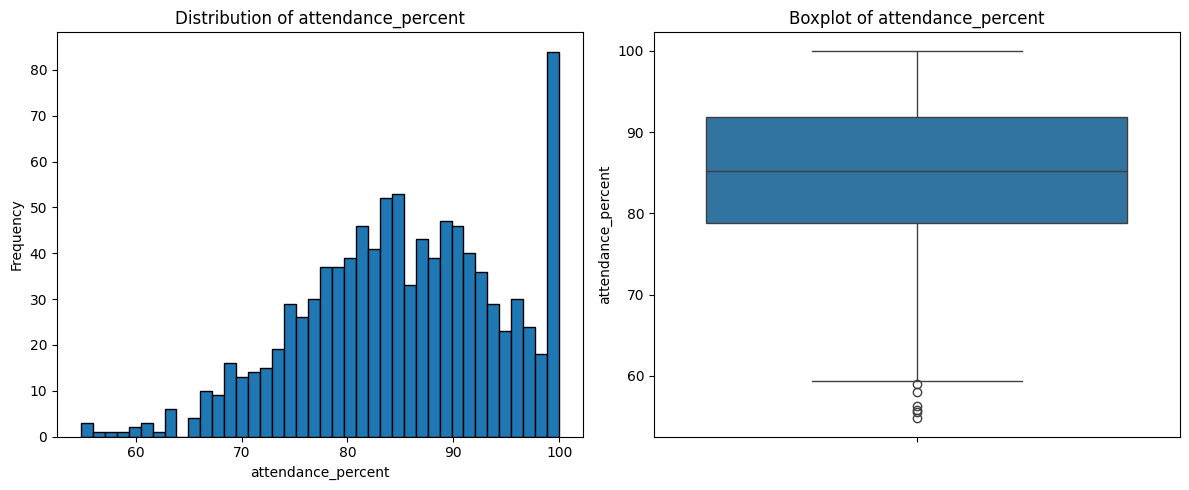

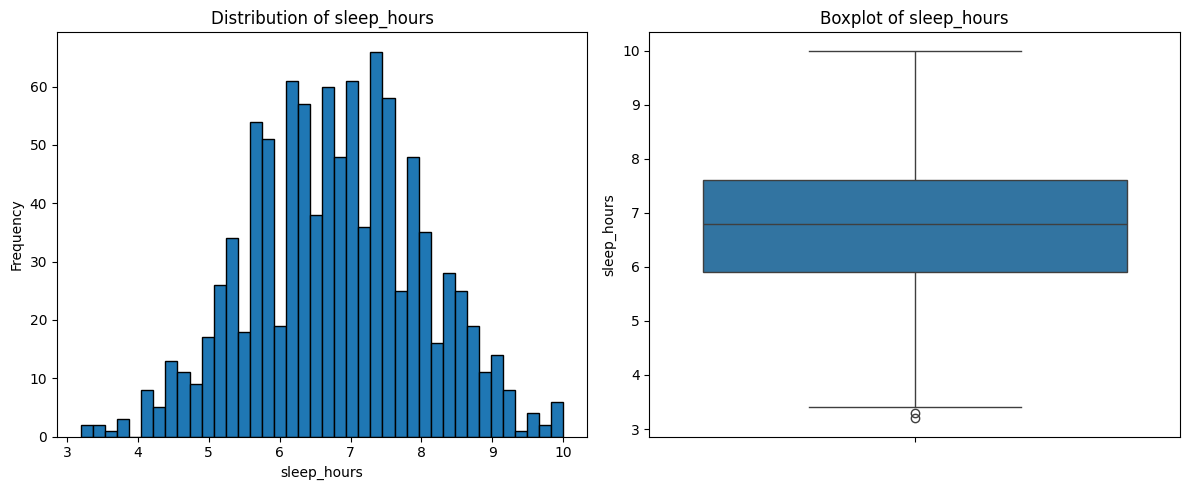

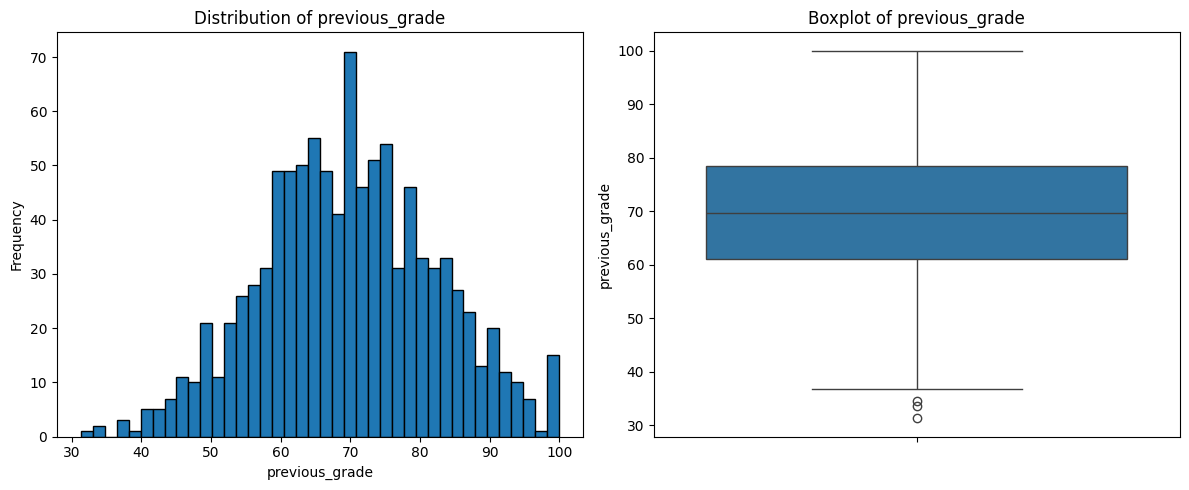

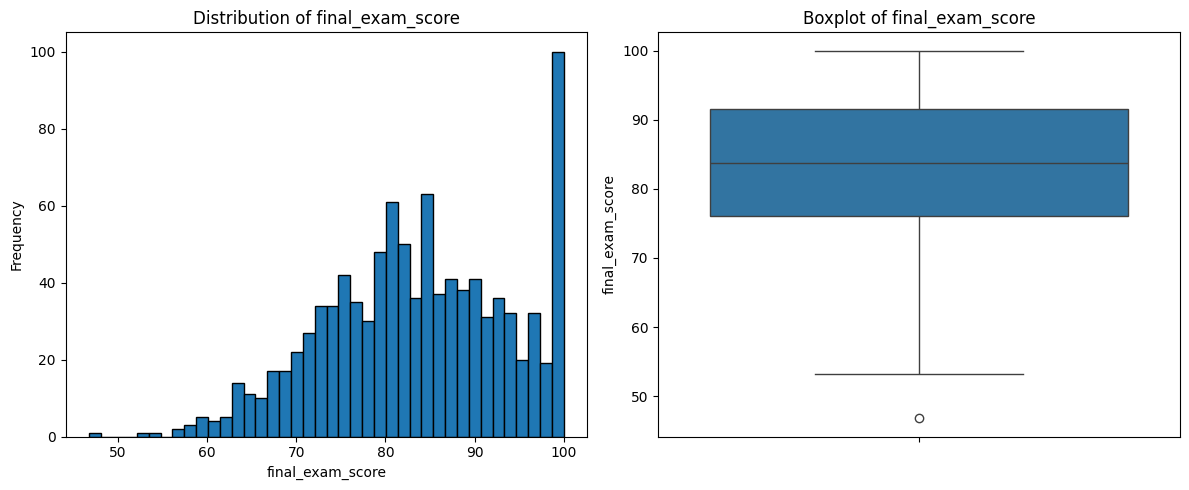

In [ ]:
for col in numerical_cols:
  # Create a new figure and a 1x2 grid of subplots for each column
  fig, axes = plt.subplots(1, 2, figsize=(12, 5))

  # Plot histogram on the first subplot
  axes[0].hist(df[col], bins=40, edgecolor='black')
  axes[0].set_title(f'Distribution of {col}')
  axes[0].set_xlabel(col)
  axes[0].set_ylabel('Frequency')

  # Plot boxplot on the second subplot
  sns.boxplot(y=df[col], ax=axes[1])
  axes[1].set_title(f'Boxplot of {col}')
  axes[1].set_ylabel(col)

  plt.tight_layout() # Adjust subplot params for a tight layout
  plt.show() # Display the plot for the current column

In [ ]:
df[numerical_cols].corr()["final_exam_score"]

,final_exam_score
study_time_hours,0.567513
attendance_percent,0.261872
sleep_hours,0.147811
previous_grade,0.406327
final_exam_score,1.000000


<Axes: >

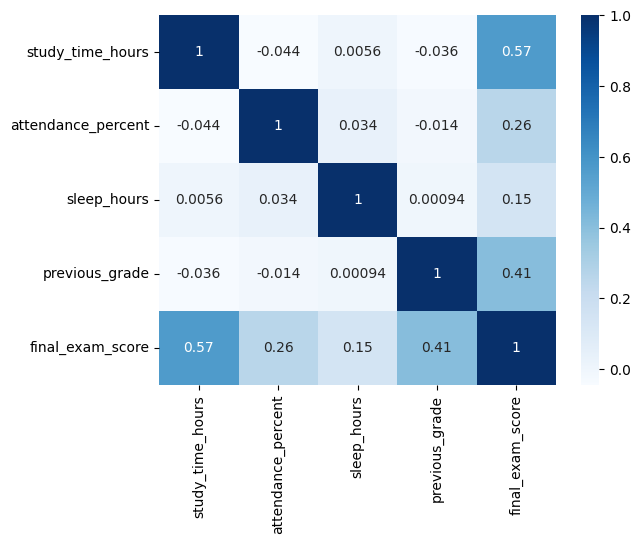

In [ ]:
sns.heatmap(data=df[numerical_cols].corr(),cmap="Blues",annot=True)

In [ ]:
?sns.heatmap

<Axes: xlabel='study_time_hours', ylabel='final_exam_score'>

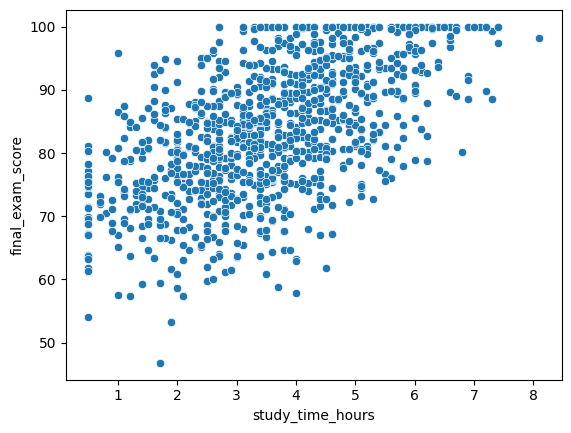

In [ ]:
sns.scatterplot(data=df,y="final_exam_score",x="study_time_hours")

For Catergorical Columns

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   object 
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          1000 non-null   object 
 6   internet_access             1000 non-null   object 
 7   extracurricular_activities  1000 non-null   object 
 8   part_time_job               1000 non-null   object 
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   object 
dtypes: float64(5), int64(1), object(6)
memory usage: 93.9+ KB


In [ ]:
categorical_cols=df.select_dtypes(include=object).columns.to_list()
categorical_cols.pop(1)

'parental_education'

In [ ]:
?plt.pie

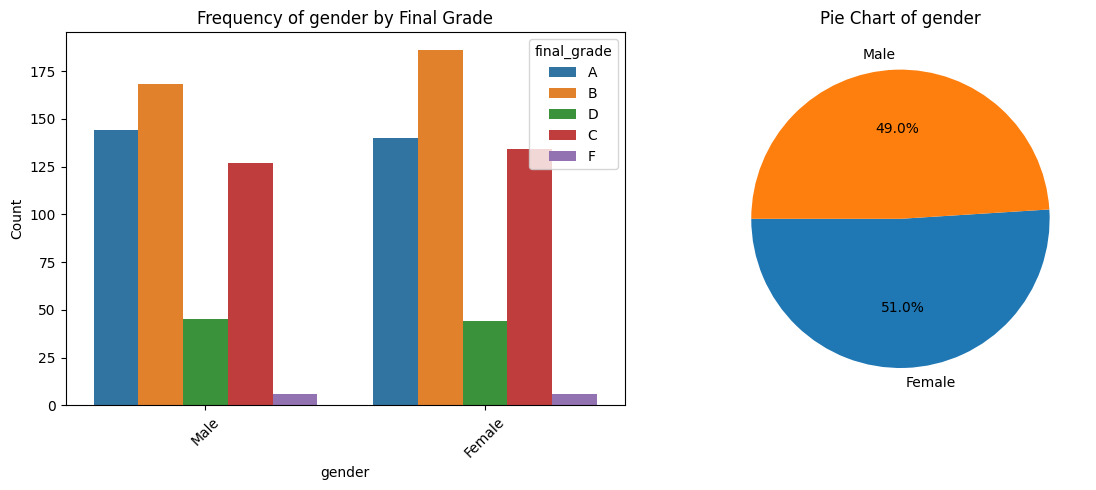

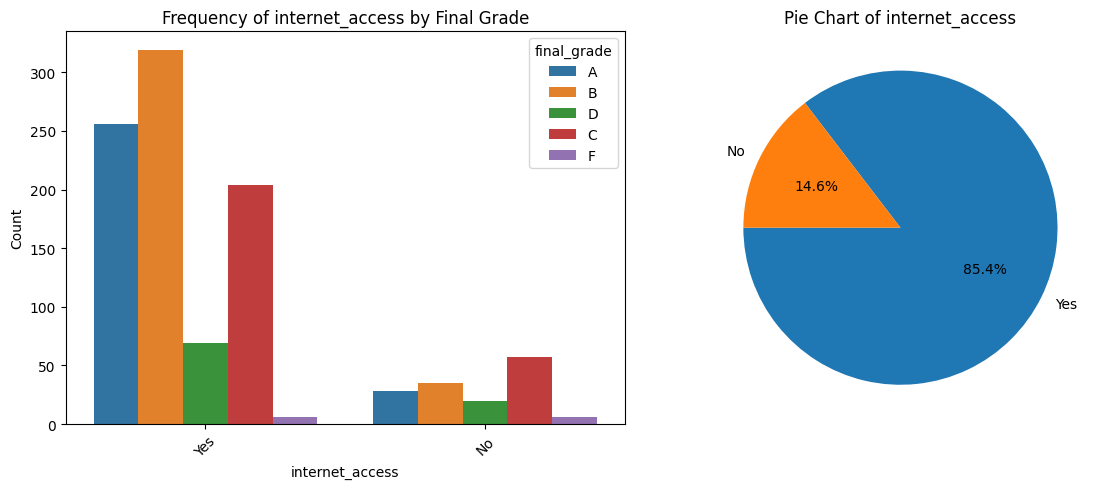

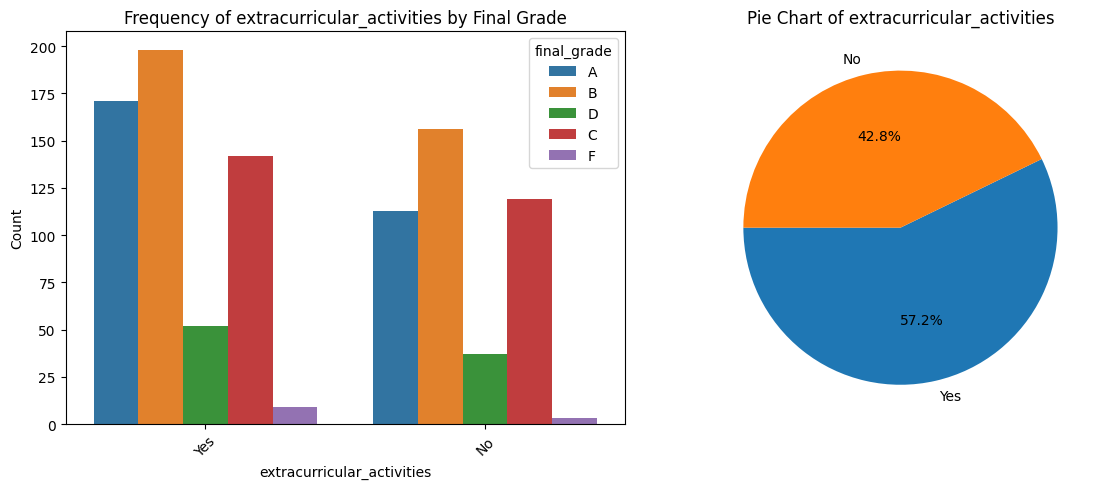

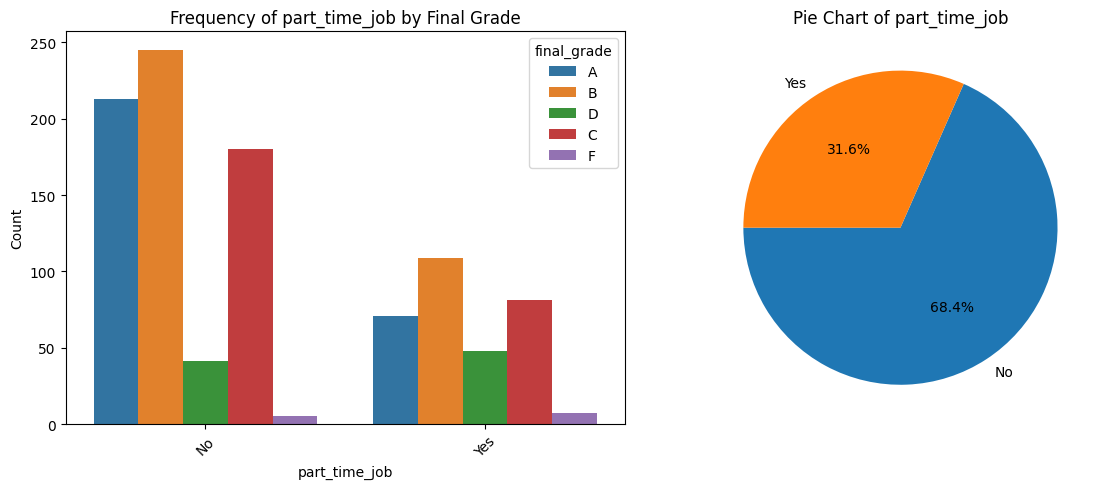

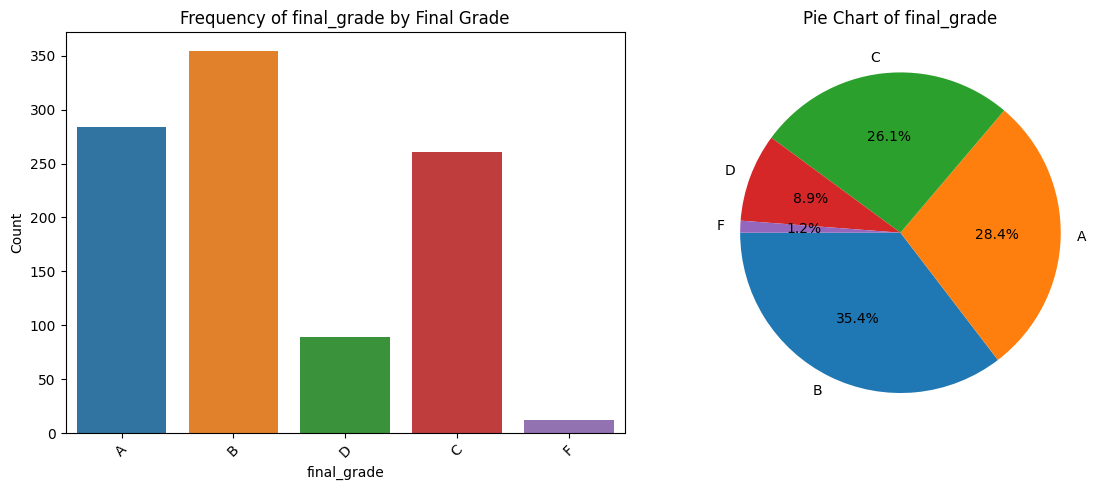

In [ ]:
for col in categorical_cols:
  fig, axes = plt.subplots(1, 2, figsize=(12, 5))

  # Plot countplot on the first subplot
  sns.countplot(data=df, x=col, hue="final_grade", ax=axes[0])
  axes[0].set_title(f"Frequency of {col} by Final Grade")
  axes[0].set_xlabel(col)
  axes[0].set_ylabel("Count")
  axes[0].tick_params(axis='x', rotation=45)

  # Plot pie chart on the second subplot
  pie_data = df[col].value_counts()
  axes[1].pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', startangle=180)
  axes[1].set_title(f"Pie Chart of {col}")
  axes[1].set_ylabel('') # Hide the default y-label

  plt.tight_layout()
  plt.show()

# Feature Engineering

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

In [ ]:
categorical_cols.pop(-1)
#cat_df=df[categorical_cols].drop(columns="final_grade")

'final_grade'

In [ ]:
categorical_cols

['gender', 'internet_access', 'extracurricular_activities', 'part_time_job']

In [ ]:
df[numerical_cols]

,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score
0,4.0,98.0,6.5,76.9,100.0
1,6.3,100.0,5.7,75.5,100.0
2,4.9,85.3,7.9,88.5,97.3
3,2.6,77.5,8.0,85.1,83.8
4,2.2,89.6,4.6,61.8,68.3
...,...,...,...,...,...
995,2.8,75.4,8.2,60.5,70.7
996,6.7,88.4,7.1,82.2,99.5
997,2.6,84.5,8.0,65.2,79.2
998,4.6,85.3,8.1,52.2,82.2


In [ ]:
encoder = OneHotEncoder(sparse_output=False,handle_unknown="ignore").fit(df[categorical_cols])

In [ ]:
features=list(encoder.get_feature_names_out(categorical_cols))
df[features]=encoder.transform(df[categorical_cols])

In [ ]:
features

['gender_Female',
 'gender_Male',
 'internet_access_No',
 'internet_access_Yes',
 'extracurricular_activities_No',
 'extracurricular_activities_Yes',
 'part_time_job_No',
 'part_time_job_Yes']

In [ ]:
df

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade,gender_Female,gender_Male,internet_access_No,internet_access_Yes,extracurricular_activities_No,extracurricular_activities_Yes,part_time_job_No,part_time_job_Yes
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
3,4,Male,2.6,77.5,8.0,<bound method Series.mode of 0 Bachelor...,Yes,Yes,No,85.1,83.8,B,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,Male,2.8,75.4,8.2,Masters,Yes,Yes,No,60.5,70.7,C,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
996,997,Male,6.7,88.4,7.1,<bound method Series.mode of 0 Bachelor...,No,Yes,No,82.2,99.5,A,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
997,998,Female,2.6,84.5,8.0,High School,Yes,Yes,Yes,65.2,79.2,C,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
998,999,Female,4.6,85.3,8.1,High School,No,No,Yes,52.2,82.2,B,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [ ]:
scaler=StandardScaler().fit(df[numerical_cols])
df[numerical_cols]=scaler.transform(df[numerical_cols])

In [ ]:
df

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade,gender_Female,gender_Male,internet_access_No,internet_access_Yes,extracurricular_activities_No,extracurricular_activities_Yes,part_time_job_No,part_time_job_Yes
0,1,Male,0.290495,1.393010,-0.248976,Bachelors,Yes,Yes,No,0.567862,1.592129,A,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
1,2,Female,1.846842,1.608852,-0.914022,High School,Yes,Yes,Yes,0.456813,1.592129,A,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2,3,Male,0.899501,0.022415,0.914853,Bachelors,Yes,No,Yes,1.487977,1.330910,A,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
3,4,Male,-0.656846,-0.819368,0.997984,<bound method Series.mode of 0 Bachelor...,Yes,Yes,No,1.218288,0.024816,B,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
4,5,Male,-0.927515,0.486475,-1.828459,Bachelors,Yes,No,Yes,-0.629874,-1.474774,D,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,Male,-0.521511,-1.046001,1.164245,Masters,Yes,Yes,No,-0.732991,-1.242579,C,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
996,997,Male,2.117511,0.356970,0.249808,<bound method Series.mode of 0 Bachelor...,No,Yes,No,0.988259,1.543755,A,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
997,998,Female,-0.656846,-0.063922,0.997984,High School,Yes,Yes,Yes,-0.360185,-0.420224,C,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
998,999,Female,0.696499,0.022415,1.081114,High School,No,No,Yes,-1.391349,-0.129981,B,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


# modeling

In [ ]:
input_df=df[numerical_cols+features]
input_df

,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score,gender_Female,gender_Male,internet_access_No,internet_access_Yes,extracurricular_activities_No,extracurricular_activities_Yes,part_time_job_No,part_time_job_Yes
0,0.290495,1.393010,-0.248976,0.567862,1.592129,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
1,1.846842,1.608852,-0.914022,0.456813,1.592129,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2,0.899501,0.022415,0.914853,1.487977,1.330910,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
3,-0.656846,-0.819368,0.997984,1.218288,0.024816,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
4,-0.927515,0.486475,-1.828459,-0.629874,-1.474774,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,-0.521511,-1.046001,1.164245,-0.732991,-1.242579,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
996,2.117511,0.356970,0.249808,0.988259,1.543755,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
997,-0.656846,-0.063922,0.997984,-0.360185,-0.420224,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
998,0.696499,0.022415,1.081114,-1.391349,-0.129981,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [ ]:
target=df["final_grade"]
target

,final_grade
0,A
1,A
2,A
3,B
4,D
...,...
995,C
996,A
997,C
998,B


In [ ]:
from sklearn.model_selection import GridSearchCV,KFold,train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score,f1_score

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(input_df,target,test_size=0.2,random_state=42)

In [ ]:
pipeline=Pipeline([
    ("logistic",LogisticRegression()),
    ("rf",RandomForestClassifier()),
    ("sv",SVC()),
])

In [ ]:
param_grids=[
    {
    "logistic":[LogisticRegression()],
    },
    {
        "rf":[RandomForestClassifier(n_jobs=-1)],
        "rf__n_estimators":[10,5,15],
        "rf__max_depth":[4,5,2]
    },
    {
        "sv":(SVC(),) #just want to store this one in a tuple
    }
            ]

In [ ]:
kf=KFold(n_splits=3)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import KFold, GridSearchCV

# Redefine pipeline with a single placeholder for the classifier
pipeline=Pipeline([
    ('classifier', 'passthrough') # 'passthrough' allows skipping this step if no specific initial estimator is desired
])

# Redefine param_grids to target the 'classifier' step
param_grids=[
    {
        "classifier":[LogisticRegression(solver='liblinear', max_iter=1000)], # Added solver and max_iter for robustness
    },
    {
        "classifier":[RandomForestClassifier(n_jobs=-1)],
        "classifier__n_estimators":[10,5,15],
        "classifier__max_depth":[4,5,2]
    },
    {
        "classifier":[SVC()]
    }
]

grid_search=GridSearchCV(
    estimator=pipeline,
    param_grid=param_grids,
    cv=kf,
    scoring="accuracy"
)
grid_search.fit(x_train,y_train)

GridSearchCV(cv=KFold(n_splits=3, random_state=None, shuffle=False),
             estimator=Pipeline(steps=[('classifier', 'passthrough')]),
             param_grid=[{'classifier': [LogisticRegression(max_iter=1000,
                                                            solver='liblinear')]},
                         {'classifier': [RandomForestClassifier(n_jobs=-1)],
                          'classifier__max_depth': [4, 5, 2],
                          'classifier__n_estimators': [10, 5, 15]},
                         {'classifier': [SVC()]}],
             scoring='accuracy')

The error you're seeing, TypeError: All intermediate steps should be transformers... 'LogisticRegression()' ... doesn't, means that your Pipeline is not set up correctly. In scikit-learn, all steps in a pipeline except the final one must be transformers, which can preprocess data. However, LogisticRegression and the other models you've included are estimators (classifiers), not transformers. To use GridSearchCV to select between different models, your pipeline should have a single placeholder step for the estimator, and your param_grids should then specify the different models and their parameters for that placeholder. I'll redefine the pipeline and param_grids within this cell to fix the issue, making the pipeline generic and specifying the different models as options for a single 'classifier' step.

In [ ]:
model=grid_search.best_estimator_
grid_search.best_score_

np.float64(0.9212732205044446)

In [ ]:
pred=model.predict(x_train)
cf=confusion_matrix(y_train,pred)
pd.Series(pred).value_counts()

,count
B,286
C,261
A,237
D,15
F,1
